# Count and aggregated citation score

Read the fixed seed input and current database in one read-only snapshot. Use the same text-ready, author-valid cohort as the author-independence experiment (expected: 4,818 citation pairs), including context and abstract-only branches. No model calls, database writes, or missing-U defaults are used.

The full-sample table preserves the previous six-column layout. A separate threshold-selected display subset uses editable bounds on the **current** self-citation-excluded count, not historical counts in the seed workbook. Three distinct illustrative cases maximize, minimize, or approach zero relative score gap. Run each output cell separately after preparation; changing the display bounds does not require another database query. The manuscript and its current figures are not modified.


## 1. Imports, paths, and editable parameters

Change `LOWER_COUNT` and `UPPER_COUNT` in Step 6; the default rule is strictly `10 < N < 100`. The final abstract-only multiplier is lambda=0.8, not another multiplication by 0.95. Alpha=0.2 and beta=0.5 retain the current scoring design. Files have stable names under `sample/count_score/` and `assets/count_score/`.

No random process is used. If SEED exists in the environment it is recorded, never reset. The pair-count assertion detects snapshot drift rather than truncating or padding the cohort.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
from IPython.display import display

from datetime import datetime, timezone
from pathlib import Path
import hashlib
import json
import os
import sys

from dotenv import load_dotenv
from sqlalchemy import URL, create_engine, select
from sqlalchemy.engine import make_url
from sqlalchemy.orm import aliased
from sqlalchemy.pool import NullPool

SRC_DIR = Path.cwd().resolve()
if not (SRC_DIR / "postgres" / "model.py").is_file():
    SRC_DIR = SRC_DIR / "src"
if not (SRC_DIR / "postgres" / "model.py").is_file():
    raise RuntimeError("Run this notebook from src/ or the repository root.")
if str(SRC_DIR) not in sys.path:
    sys.path.insert(0, str(SRC_DIR))

from postgres.model import Author, Citation, Paper, PaperAuthor

# Existing inputs only; no database extract is written to Excel.
SEED_FILE = SRC_DIR / "sample" / "seed_papers_final.xlsx"
OUTPUT_DIR = SRC_DIR / "sample" / "count_score"
ASSET_DIR = SRC_DIR / "assets"
ALPHA = 0.2
CONTEXT_DISCOUNT = 0.8  # Existing final multiplier, not 0.95 * 0.8 again.
CONTEXT_ONLY = False  # True restricts the analysis to context-bearing pairs.
BETA = 0.5
EXPECTED_PAIRS = 4818  # Guard against unreviewed database/cohort changes.
SAVE_RESULTS = True
EXPORT_RECORDS = False  # Opt-in local identifiers/individual scores; never auto-publish.
# No random selection is used. Respect the existing environment seed.
load_dotenv(SRC_DIR.parent / ".env", override=False)
load_dotenv(SRC_DIR / ".env", override=False)
RANDOM_STATE = int(os.environ["SEED"]) if os.getenv("SEED") else None


def load_seed_ids(path):
    seeds = pd.read_excel(path, usecols=["id"])
    values = pd.to_numeric(seeds["id"], errors="raise")
    if (values.isna().any() or values.le(0).any()
            or values.mod(1).ne(0).any() or values.duplicated().any()):
        raise ValueError("Seed IDs must be distinct positive integers.")
    if len(values) != 400:
        raise ValueError("Expected the fixed 400-seed input.")
    return values.astype("int64").tolist()


def read_author_citations(seed_ids):
    """Read citation and author inputs in one read-only database snapshot."""
    load_dotenv(SRC_DIR.parent / ".env", override=False)
    load_dotenv(SRC_DIR / ".env", override=False)
    if os.getenv("DATABASE_URL"):
        url = make_url(os.environ["DATABASE_URL"]).set(drivername="postgresql+psycopg")
    else:
        if not os.getenv("POSTGRES_USER") or not os.getenv("POSTGRES_DB"):
            raise RuntimeError("Set POSTGRES_USER and POSTGRES_DB, or DATABASE_URL.")
        url = URL.create(
            "postgresql+psycopg",
            username=os.environ["POSTGRES_USER"],
            password=os.getenv("POSTGRES_PASS") or os.getenv("POSTGRES_PASSWORD"),
            host=os.getenv("POSTGRES_HOST", "localhost"),
            port=int(os.getenv("POSTGRES_PORT", "5432")),
            database=os.environ["POSTGRES_DB"],
        )
    engine = create_engine(
        url, poolclass=NullPool, isolation_level="REPEATABLE READ",
        connect_args={
            "connect_timeout": 10,
            "options": "-c default_transaction_read_only=on "
                       "-c statement_timeout=120000 -c lock_timeout=5000",
        },
    )
    citing, cited = aliased(Paper), aliased(Paper)
    query = (
        select(
            Citation.citing_corpus_id, Citation.cited_corpus_id, Citation.contexts,
            Citation.cross_score, Citation.llm_score,
            Citation.abstract_cross_score, Citation.abstract_llm_score,
            Citation.author_independence,
            citing.abstract.label("citing_abstract"),
            cited.abstract.label("cited_abstract"),
            cited.title.label("cited_title"), cited.doi.label("cited_doi"),
            citing.year.label("citing_year"),
            citing.publication_date.label("citing_publication_date"),
        )
        .select_from(Citation)
        .outerjoin(citing, citing.corpus_id == Citation.citing_corpus_id)
        .outerjoin(cited, cited.corpus_id == Citation.cited_corpus_id)
        .where(Citation.cited_corpus_id.in_(seed_ids))
        .order_by(Citation.cited_corpus_id, Citation.citing_corpus_id)
    )
    try:
        with engine.connect() as connection, connection.begin():
            citation_result = connection.execute(query)
            citations = pd.DataFrame(
                citation_result.fetchall(), columns=list(citation_result.keys())
            )
            paper_ids = sorted(set(seed_ids) | set(citations["citing_corpus_id"]))
            author_query = (
                select(
                    PaperAuthor.paper_id, PaperAuthor.author_id,
                    PaperAuthor.author_order, Author.name.label("author_name"),
                )
                .outerjoin(Author, Author.author_id == PaperAuthor.author_id)
                .where(PaperAuthor.paper_id.in_(paper_ids))
                .order_by(PaperAuthor.paper_id, PaperAuthor.author_order)
            )
            author_result = connection.execute(author_query)
            authors = pd.DataFrame(
                author_result.fetchall(), columns=list(author_result.keys())
            )
    except Exception as error:
        # Do not expose the connection URL, password, or query parameters.
        raise RuntimeError(
            f"Read-only database query failed ({type(error).__name__}). "
            "Check the connection and schema locally."
        ) from None
    finally:
        engine.dispose()
    return citations, authors



## 2. Eligibility checks

Reuse the author-independence experiment's checks: cited abstract, context first (citing abstract only if context is unavailable), valid active-branch scores, valid author lists on both papers, and recorded U in [0,1]. A zero score or U=0 is valid. Missing active scores cannot trigger a fallback to the other branch. Dates are not used as a filter. These functions do not recalculate the stored collaboration graph.


In [2]:
def usable_text(value):
    return isinstance(value, str) and bool(value.strip())


def context_status(value):
    """Return (available, valid); malformed JSONB is not silently abstract-only."""
    if value is None:
        return False, True
    if isinstance(value, str):
        return usable_text(value), True
    if isinstance(value, dict):
        for key in ("text", "context", "sentence"):
            if key in value:
                return context_status(value[key])
        return False, False
    if isinstance(value, list):
        items = [context_status(item) for item in value]
        return any(available for available, _ in items), all(valid for _, valid in items)
    return False, False


def checked_unit_score(series):
    values = pd.to_numeric(series, errors="coerce")
    not_boolean = ~series.map(lambda x: isinstance(x, (bool, np.bool_)))
    return values.where(np.isfinite(values) & values.between(0, 1) & not_boolean)


def authors_ready(group):
    """Database-observable coverage, not proof of exhaustive author/history data."""
    ids = pd.to_numeric(group["author_id"], errors="coerce")
    order = pd.to_numeric(group["author_order"], errors="coerce")
    if (ids.isna().any() or ids.le(0).any() or ids.mod(1).ne(0).any()
            or ids.duplicated().any() or order.isna().any()
            or order.mod(1).ne(0).any() or order.duplicated().any()
            or not group["author_name"].map(usable_text).all()):
        return False
    first = int(order.min())
    return first in (0, 1) and sorted(order.astype(int)) == list(
        range(first, first + len(group))
    )


def prepare_author_cohort(citations, authors, seed_ids, alpha=0.2,
                          context_discount=0.8, context_only=False):
    if not 0 <= alpha <= 1 or not 0 < context_discount < 0.95:
        raise ValueError("Invalid alpha or final context discount.")
    d = citations.copy()
    if d.duplicated(["citing_corpus_id", "cited_corpus_id"]).any():
        raise ValueError("Duplicate citation pairs in database query.")
    ready_papers = {
        int(paper_id) for paper_id, group in authors.groupby("paper_id")
        if authors_ready(group)
    }
    statuses = d["contexts"].map(context_status)
    has_context = statuses.map(lambda x: x[0])
    valid_context = statuses.map(lambda x: x[1])
    has_cited = d["cited_abstract"].map(usable_text)
    has_citing = d["citing_abstract"].map(usable_text)
    d["branch"] = np.where(has_context, "context", "abstract")
    # Context always takes priority; missing context scores do not trigger fallback.
    cross = checked_unit_score(d["cross_score"]).where(
        has_context, checked_unit_score(d["abstract_cross_score"])
    )
    llm = checked_unit_score(d["llm_score"]).where(
        has_context, checked_unit_score(d["abstract_llm_score"])
    )
    d["cross"] = cross
    d["llm"] = llm
    d["U"] = checked_unit_score(d["author_independence"])
    weight = np.where(has_context, 1.0, context_discount)
    d["base"] = (alpha * cross + (1 - alpha) * llm) * weight

    coverage = [("Seed papers in fixed input", len(seed_ids)),
                ("Stored citation pairs to seeds", len(d))]
    retained = pd.Series(True, index=d.index)
    filters = [
        ("After cited-abstract requirement", has_cited),
        ("After context/abstract input requirement",
         valid_context & (has_context | has_citing)),
        ("After requested context-branch restriction",
         has_context if context_only else pd.Series(True, index=d.index)),
        ("After valid active semantic scores", cross.notna() & llm.notna()),
        ("After author-list coverage on both papers",
         d["cited_corpus_id"].isin(ready_papers)
         & d["citing_corpus_id"].isin(ready_papers)),
        ("After valid recorded author-independence score", d["U"].notna()),
    ]
    for label, requirement in filters:
        retained &= requirement
        coverage.append((label, int(retained.sum())))
    cohort = d.loc[retained, [
        "citing_corpus_id", "cited_corpus_id", "branch", "cross", "llm", "U", "base"
    ]].copy()
    coverage.extend([
        ("Retained seed papers represented", cohort["cited_corpus_id"].nunique()),
        ("Retained context-bearing pairs", int(cohort["branch"].eq("context").sum())),
        ("Retained abstract-only pairs", int(cohort["branch"].eq("abstract").sum())),
        ("Retained pairs with U < 1", int(cohort["U"].lt(1).sum())),
        ("Retained zero-baseline pairs", int(cohort["base"].eq(0).sum())),
    ])
    coverage = pd.DataFrame(coverage, columns=["stage", "count"])
    distribution = (
        cohort.groupby(["branch", "U"], sort=True).size().rename("count").reset_index()
    )
    return cohort, coverage, distribution


## 3. Load one snapshot and prepare citation scores

N counts eligible citations with U>0.5, excluding recorded shared-author self-citations. S sums the weighted citation scores over the same eligible input pool; shared-author citations retain their down-weighted contribution to S, as in the original comparison.

For each pair:
- semantic = alpha × cross + (1-alpha) × LLM;
- relevance = semantic × context_weight, with weight 1 for context and lambda for abstract-only;
- score = relevance × (1-beta+beta×U).

Context and author penalties are signed differences. Their sum with the two semantic components equals the final score. Raw abstracts/contexts and author names are kept in memory only and are never exported by default.


In [3]:
seeds = pd.read_excel(SEED_FILE)
seed_ids = load_seed_ids(SEED_FILE)
citations, authors = read_author_citations(seed_ids)
database_query_utc = datetime.now(timezone.utc).isoformat(timespec="seconds")
cohort, coverage, u_distribution = prepare_author_cohort(
    citations, authors, seed_ids, alpha=ALPHA,
    context_discount=CONTEXT_DISCOUNT, context_only=CONTEXT_ONLY,
)
display(coverage)
if EXPECTED_PAIRS is not None and len(cohort) != EXPECTED_PAIRS:
    raise RuntimeError(
        f"Expected {EXPECTED_PAIRS:,} eligible pairs, found {len(cohort):,}. "
        "Review coverage and database changes before accepting a new cohort."
    )
if cohort.empty:
    raise RuntimeError("No eligible citation pairs.")

metadata_columns = [
    "citing_corpus_id", "cited_corpus_id", "cited_title", "cited_doi",
    "citing_year", "citing_publication_date",
]
scored_citations = cohort.merge(
    citations[metadata_columns], on=["citing_corpus_id", "cited_corpus_id"],
    validate="one_to_one",
).rename(columns={"citing_corpus_id": "citing_id", "cited_corpus_id": "cited_id"})
scored_citations["context_weight"] = np.where(
    scored_citations["branch"].eq("context"), 1.0, CONTEXT_DISCOUNT
)
scored_citations["cross_component"] = ALPHA * scored_citations["cross"]
scored_citations["llm_component"] = (1 - ALPHA) * scored_citations["llm"]
scored_citations["semantic_score"] = (
    scored_citations["cross_component"] + scored_citations["llm_component"]
)
scored_citations["context_penalty"] = scored_citations["base"] - scored_citations["semantic_score"]
scored_citations["author_weight"] = 1 - BETA + BETA * scored_citations["U"]
scored_citations["citation_score"] = scored_citations["base"] * scored_citations["author_weight"]
scored_citations["author_penalty"] = scored_citations["citation_score"] - scored_citations["base"]
scored_citations["count_contribution"] = scored_citations["U"].gt(0.5).astype(int)
# Single-model comparators use the same context discount, without author correction.
scored_citations["cross_only_score"] = scored_citations["cross"] * scored_citations["context_weight"]
scored_citations["llm_only_score"] = scored_citations["llm"] * scored_citations["context_weight"]
np.testing.assert_allclose(
    scored_citations[["cross_component", "llm_component", "context_penalty", "author_penalty"]].sum(axis=1),
    scored_citations["citation_score"], rtol=1e-12, atol=1e-12,
)
print(f"Eligible pairs: {len(scored_citations):,}; "
      f"context: {scored_citations['branch'].eq('context').sum():,}; "
      f"abstract-only: {scored_citations['branch'].eq('abstract').sum():,}.")


,stage,count
0,Seed papers in fixed input,400
1,Stored citation pairs to seeds,9655
2,After cited-abstract requirement,9655
3,After context/abstract input requirement,7987
4,After requested context-branch restriction,7987
5,After valid active semantic scores,7987
6,After author-list coverage on both papers,4818
7,After valid recorded author-independence score,4818
8,Retained seed papers represented,398
9,Retained context-bearing pairs,4737


Eligible pairs: 4,818; context: 4,737; abstract-only: 81.


## 4. Paper-level aggregation and full-sample table helpers

Keep all fixed seed rows in the coverage calculation. Papers with no eligible pairs have unavailable N and S, not fabricated zero scores; only analyzable papers enter correlations and ranks. A paper whose eligible pairs are all self-citations has a genuine N=0 and is retained.

The manuscript-style table has the previous columns: Field, Evaluable pairs, N, S, Spearman, and absolute rank change. Medians and [Q1,Q3] are descriptive quartiles, not confidence intervals. S is unnormalized here. Ranks use the full analyzable set with average ranks for ties; field correlations are computed within each field.


In [4]:
def aggregate_count_score(citations, seeds, stored_pair_counts):
    if seeds["id"].duplicated().any():
        raise ValueError("Seed identifiers must be unique.")
    if citations.duplicated(["citing_id", "cited_id"]).any():
        raise ValueError("Duplicate citation pairs.")
    if not citations["cited_id"].isin(seeds["id"]).all():
        raise ValueError("Citation outside the fixed seed input.")
    d = citations.copy()
    grouped = d.groupby("cited_id").agg(
        retained_pairs=("citing_id", "size"),
        retained_context_pairs=("branch", lambda x: x.eq("context").sum()),
        retained_abstract_pairs=("branch", lambda x: x.eq("abstract").sum()),
        count=("count_contribution", "sum"),
        score_raw=("citation_score", "sum"),
        cross_raw=("cross_only_score", "sum"),
        llm_raw=("llm_only_score", "sum"),
    ).rename_axis("id").reset_index()
    p = seeds.copy().merge(grouped, on="id", how="left", validate="one_to_one")
    p["analyzable"] = p["retained_pairs"].notna()
    for name in ("retained_pairs", "retained_context_pairs", "retained_abstract_pairs"):
        p[name] = p[name].fillna(0).astype(int)
    p["stored_pairs"] = p["id"].map(stored_pair_counts).fillna(0).astype(int)
    p["in_scope_pairs"] = p["stored_pairs"]
    p["excluded_pairs"] = p["stored_pairs"] - p["retained_pairs"]
    p["defaulted_author_pairs"] = 0
    p["self_citation_count"] = p["retained_pairs"] - p["count"]
    p["display_subset"] = False
    for column, rank in (("count", "rank_count"), ("score_raw", "rank_score")):
        p[rank] = p[column].rank(ascending=False, method="average")
    p["rank_change"] = p["rank_count"] - p["rank_score"]
    p["absolute_rank_change"] = p["rank_change"].abs()
    assert p["retained_pairs"].sum() == len(citations)
    assert p["retained_context_pairs"].sum() + p["retained_abstract_pairs"].sum() == len(citations)
    np.testing.assert_allclose(p["score_raw"].sum(), citations["citation_score"].sum())
    np.testing.assert_allclose(p["count"].sum(), citations["count_contribution"].sum())
    return p.sort_values("id").reset_index(drop=True)


def make_summary_tables(papers, lower_count=10, upper_count=100):
    """All-seed and per-field summaries. Ranks always use the same all-seed reference."""
    cohorts = [("Overall", papers)]
    if "field" in papers:
        cohorts += [(str(name), frame) for name, frame in papers.groupby("field", dropna=False)]
    rows = []
    for name, requested in cohorts:
        analyzed = requested.loc[requested["analyzable"]]
        row = {
            "cohort": name, "seed_papers": len(requested), "papers_analyzed": len(analyzed),
            "stored_pairs": int(requested["stored_pairs"].sum()),
            "in_scope_pairs": int(requested["in_scope_pairs"].sum()),
            "retained_pairs": int(requested["retained_pairs"].sum()),
            "excluded_pairs": int(requested["excluded_pairs"].sum()),
            "retained_context_pairs": int(requested["retained_context_pairs"].sum()),
            "retained_abstract_pairs": int(requested["retained_abstract_pairs"].sum()),
            "defaulted_author_pairs": int(requested["defaulted_author_pairs"].sum()),
        }
        for column, label in (("citation_count", "seed_reported_citations"),
                              ("valid_citation_count", "seed_context_citations")):
            row[label] = int(requested[column].sum()) if column in requested else np.nan
        for column, prefix in (("count", "N"), ("score_raw", "S"),
                               ("absolute_rank_change", "abs_rank_change")):
            for quantile, suffix in ((0.25, "q1"), (0.5, "median"), (0.75, "q3")):
                row[f"{prefix}_{suffix}"] = float(analyzed[column].quantile(quantile))
        row["spearman"] = float(spearmanr(analyzed["count"], analyzed["score_raw"]).statistic) if (
            len(analyzed) >= 2 and analyzed["count"].nunique() > 1
            and analyzed["score_raw"].nunique() > 1
        ) else np.nan
        rows.append(row)
    statistics = pd.DataFrame(rows)

    def interval(row, prefix):
        values = [row[f"{prefix}_{suffix}"] for suffix in ("median", "q1", "q3")]
        return f"{values[0]:.2f} [{values[1]:.2f}, {values[2]:.2f}]" if (
            np.isfinite(values).all()
        ) else "NA"

    table = pd.DataFrame([{
        "Cohort": row["cohort"], "Seeds": row["seed_papers"],
        "Analyzed": row["papers_analyzed"], "Retained pairs": row["retained_pairs"],
        "N median [Q1, Q3]": interval(row, "N"), "S median [Q1, Q3]": interval(row, "S"),
        "Spearman": f"{row['spearman']:.3f}" if np.isfinite(row["spearman"]) else "NA",
        "|Rank change| median [Q1, Q3]": interval(row, "abs_rank_change"),
    } for row in rows])
    return statistics, table


def make_paper_summary_latex(statistics, save_path=None, mark_revision=False):
    """Format existing numerical summaries; no queries, rescoring, or new statistics.

    N excludes recorded shared-author self-citations (U <= 0.5).
    S is the raw weighted sum. Field correlations are within-field, whereas
    absolute rank changes retain the full analyzable-paper reference used by the plot.
    Medians and [Q1, Q3] share one line to keep each table row unambiguous.
    """
    required = {"cohort", "retained_pairs", "spearman"}
    required.update(f"{prefix}_{suffix}" for prefix in ("N", "S", "abs_rank_change")
                    for suffix in ("median", "q1", "q3"))
    if required.difference(statistics.columns):
        raise ValueError(f"Missing summary columns: {sorted(required.difference(statistics.columns))}")
    if statistics.empty or statistics["cohort"].isna().any() or statistics["cohort"].duplicated().any():
        raise ValueError("Summary cohorts must be nonempty, named, and unique.")

    def mark(value):
        return r"\revision{" + value + "}" if mark_revision else value

    def escape(value):
        replacements = {"\\": r"\textbackslash{}", "&": r"\&", "%": r"\%",
                        "$": r"\$", "#": r"\#", "_": r"\_", "{": r"\{",
                        "}": r"\}", "~": r"\textasciitilde{}", "^": r"\textasciicircum{}"}
        return "".join(replacements.get(char, char) for char in str(value))

    def quartiles(row, prefix):
        values = np.asarray([row[f"{prefix}_{suffix}"] for suffix in ("median", "q1", "q3")],
                            dtype=float)
        if not np.isfinite(values).all():
            return mark("--")
        median, q1, q3 = values
        if not 0 <= q1 <= median <= q3:
            raise ValueError(f"Invalid quartiles for {row['cohort']}: {prefix}")
        return mark(f"{median:.2f} [{q1:.2f}, {q3:.2f}]")

    headers = ["Field", "Evaluable pairs", r"$N_j$", r"$S_j$", "Spearman", r"$|\Delta k_j|$"]
    lines = [r"\begin{table*}[!t]", r"    \centering",
             r"    \caption{" + mark("Paper-level count--score statistics.") + "}",
             r"    \label{tab:paper-summary}", r"    \small",
             r"    \setlength{\tabcolsep}{5pt}", r"    \begin{tabular}{@{}lrcccc@{}}",
             r"        \toprule", "        " + " & ".join(map(mark, headers)) + r" \\",
             r"        \midrule"]
    for _, row in statistics.iterrows():
        count = float(row["retained_pairs"])
        if not np.isfinite(count) or count < 0 or count != int(count):
            raise ValueError("Evaluable-pair counts must be nonnegative integers.")
        rho = float(row["spearman"])
        if np.isfinite(rho) and not -1 <= rho <= 1:
            raise ValueError("Spearman must lie in [-1, 1].")
        cohort = "Overall" if row["cohort"] == "All seed papers" else row["cohort"]
        cells = [mark(escape(cohort)), mark(f"{int(count):,}"), quartiles(row, "N"),
                 quartiles(row, "S"), mark(f"{rho:.3f}" if np.isfinite(rho) else "--"),
                 quartiles(row, "abs_rank_change")]
        lines.append("        " + " & ".join(cells) + r" \\")
    lines.extend([r"        \bottomrule", r"    \end{tabular}", r"\end{table*}"])
    latex = "\n".join(lines) + "\n"
    if save_path is not None:
        path = Path(save_path)
        path.parent.mkdir(parents=True, exist_ok=True)
        path.write_text(latex, encoding="utf-8")
    return latex


## 5. Generate the full-sample summary table

Aggregate before applying the display bounds. The six-column table matches the previous table's structure and can be rerun independently of the later case-selection cells. Outputs contain aggregate statistics only.


In [5]:
citations_raw_counts = citations.groupby("cited_corpus_id").size()
papers = aggregate_count_score(scored_citations, seeds, citations_raw_counts)
summary_statistics, summary_table = make_summary_tables(papers)
display(summary_table.drop(columns=["Seeds", "Analyzed"]))
if SAVE_RESULTS:
    OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
    summary_statistics.to_csv(OUTPUT_DIR / "summary_statistics.csv", index=False)
    summary_table.drop(columns=["Seeds", "Analyzed"]).to_csv(OUTPUT_DIR / "summary_table.csv", index=False)
    coverage.to_csv(OUTPUT_DIR / "coverage.csv", index=False)
    make_paper_summary_latex(
        summary_statistics, save_path=OUTPUT_DIR / "paper_summary_table.tex"
    )


,Cohort,Retained pairs,"N median [Q1, Q3]","S median [Q1, Q3]",Spearman,"|Rank change| median [Q1, Q3]"
0,Overall,4818,"4.00 [2.00, 9.00]","3.21 [1.63, 6.07]",0.930,"19.00 [7.12, 37.00]"
1,Biology,472,"5.00 [2.25, 11.75]","3.61 [1.90, 8.21]",0.906,"15.00 [5.00, 28.50]"
2,Chemistry,369,"3.50 [2.00, 6.75]","2.15 [1.19, 4.27]",0.951,"17.25 [7.12, 36.12]"
3,Computer Science,2017,"12.00 [5.25, 33.75]","6.75 [4.58, 16.45]",0.974,"16.50 [2.25, 31.62]"
4,Economics,329,"3.00 [2.00, 7.75]","1.80 [1.04, 4.30]",0.953,"18.50 [7.62, 35.00]"
5,Engineering,360,"3.00 [2.00, 7.00]","2.47 [1.73, 4.65]",0.835,"25.00 [14.50, 42.00]"
6,Medicine,294,"4.00 [2.00, 6.75]","2.79 [1.83, 4.15]",0.927,"22.00 [10.62, 37.50]"
7,Physics,433,"5.00 [3.00, 9.00]","3.92 [2.72, 7.02]",0.914,"18.00 [9.00, 40.00]"
8,Psychology,544,"3.50 [2.00, 10.00]","2.57 [1.56, 5.90]",0.953,"12.50 [6.50, 35.62]"


## 6. Select the display subset and three cases

Edit the two bounds in this cell and rerun from here; no new database request is needed. The rule is strictly lower < N < upper. Do not prefilter using the seed workbook's historical citation counts.

Mean matching is calculated once across this display subset: score_factor = mean(N)/mean(raw S). The same factor applies to every paper and citation in the subset. S_gap=(normalized S-N)/N. Select its maximum, minimum, and smallest absolute value, with distinct cases and Corpus ID as a deterministic tie-breaker. Positive/negative labels are descriptive; inspect the signs rather than assuming them. Single-model comparator curves have their own subset-wide mean-matching factors, never per-case normalization.


In [6]:
def select_display_cases(papers, citations, lower_count=10, upper_count=100):
    if (not np.isfinite(lower_count) or lower_count < 0
            or (upper_count is not None and
                (not np.isfinite(upper_count) or upper_count <= lower_count))):
        raise ValueError("Require 0 <= lower < upper, or upper=None.")
    mask = papers["analyzable"] & papers["count"].gt(lower_count)
    if upper_count is not None:
        mask &= papers["count"].lt(upper_count)
    p = papers.loc[mask].copy().sort_values("id").reset_index(drop=True)
    if len(p) < 3:
        raise ValueError("Fewer than three papers meet the current count bounds.")
    factors = {}
    for column, name in (("score_raw", "score_factor"), ("cross_raw", "cross_factor"), ("llm_raw", "llm_factor")):
        mean = float(p[column].mean())
        if not np.isfinite(mean) or mean <= 0:
            raise ValueError(f"Cannot mean-match {column}: mean must be positive.")
        factors[name] = float(p["count"].mean() / mean)
    p["total_score"] = p["score_raw"] * factors["score_factor"]
    p["diff"] = (p["total_score"] - p["count"]) / p["count"]
    p["absolute_diff"] = p["diff"].abs()
    largest = p.sort_values(["diff", "id"], ascending=[False, True]).index[0]
    smallest = p.drop(index=largest).sort_values(["diff", "id"]).index[0]
    closest = p.drop(index=[largest, smallest]).sort_values(["absolute_diff", "id"]).index[0]
    p["case"] = ""
    for index, label in zip(
        [largest, smallest, closest],
        ["largest_positive_gap", "largest_negative_gap", "closest_to_equal"],
    ):
        p.loc[index, "case"] = label
    cases = p.loc[[largest, smallest, closest]].copy()
    selected = citations.loc[citations["cited_id"].isin(p["id"])].copy()
    for raw, scaled, factor in (
        ("citation_score", "score_mm", "score_factor"),
        ("cross_only_score", "cross_mm", "cross_factor"),
        ("llm_only_score", "llm_mm", "llm_factor"),
    ):
        selected[scaled] = selected[raw] * factors[factor]
    np.testing.assert_allclose(p["total_score"].mean(), p["count"].mean())
    return {"papers": p, "cases": cases, "citations": selected, "factors": factors,
            "lower_count": lower_count, "upper_count": upper_count}


# Change these bounds and rerun this cell and the output cells below.
LOWER_COUNT = 10
UPPER_COUNT = 100
result = select_display_cases(papers, scored_citations, LOWER_COUNT, UPPER_COUNT)
print(f"Display subset: {len(result['papers'])} papers; "
      f"{LOWER_COUNT} < N < {UPPER_COUNT if UPPER_COUNT is not None else 'infinity'}.")
case_preview = result["cases"].copy()
if not EXPORT_RECORDS:
    case_preview = case_preview.drop(columns="id")
display(case_preview[
    ["case", *(["id"] if EXPORT_RECORDS else []), "field", "count", "score_raw", "total_score", "diff",
     "retained_pairs", "retained_abstract_pairs"]
].rename(columns={"id": "cited_id", "diff": "S_gap"}))


Display subset: 84 papers; 10 < N < 100.


,case,field,count,score_raw,total_score,S_gap,retained_pairs,retained_abstract_pairs
2,largest_positive_gap,Biology,11.0,10.025933,15.632391,0.421126,13,0
28,largest_negative_gap,Computer Science,43.0,12.018672,18.739461,-0.564199,43,0
68,closest_to_equal,Biology,21.0,13.451238,20.973112,-0.001280,22,0


## 7. Define the summary, display, and citation-detail plots

The comparison uses the same S_gap definition as before. Detail plots show cumulative values, per-citation differences, and actual score components. Context and author penalties are separate negative components. Single-model cumulative curves apply the context discount but no author correction. The citation order is ascending citing Corpus ID, an indexing convention, **not time or evidence of temporal convergence**. No paper IDs or titles appear in the saved figures.

The display comparison uses a 10 by 6.3 inch landscape canvas for a rotated full-page figure, with all paper indices shown. Detail plots use a 9 by 4.3 inch canvas and compact panel spacing; the component legend sits between the second and third panels. Case identity is left to the manuscript caption.


In [7]:
def plot_full_paper_summary(
    papers, size=(6.5, 3.0), save_path=None, log_axes=True,
    lower_count=10, upper_count=100,
):
    """All-seed count-score scatter and signed global-rank-change histogram."""
    df = papers.loc[papers["analyzable"]].copy()
    if df.empty:
        raise ValueError("No seeds with evaluable citations are available for plotting.")
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=size, layout="constrained")
    x, y = df["count"], df["score_raw"]
    if log_axes:
        x, y = np.log1p(x), np.log1p(y)
    ax1.scatter(x, y, s=10, alpha=0.7, color="#2878B5")
    ax1.set_xlabel(r"$\log(1+N_j)$" if log_axes else r"$N_j$")
    ax1.set_ylabel(r"$\log(1+S_j)$" if log_axes else r"$S_j$")
    ax1.set_title("(a) Count and score", loc="left", fontsize=9)
    extent = float(df["rank_change"].abs().max())
    bins = np.array([-0.5, 0.5]) if extent == 0 else np.linspace(-extent - 0.5, extent + 0.5, 32)
    ax2.hist(df["rank_change"], bins=bins, color="#2878B5", edgecolor="white")
    ax2.axvline(0, color="black", linestyle="--", linewidth=0.8)
    ax2.set_xlabel(r"$\Delta k_j=k_j^N-k_j^S$ (positive = up)")
    ax2.set_ylabel("Number of papers")
    ax2.set_title("(b) Rank changes", loc="left", fontsize=9)
    for axis in (ax1, ax2):
        axis.tick_params(labelsize=8)
        axis.grid(alpha=0.2)
        axis.set_axisbelow(True)
    
    if save_path:
        path = Path(save_path)
        path.parent.mkdir(parents=True, exist_ok=True)
        fig.savefig(path, bbox_inches="tight")
    return fig


CASE_STYLE = {
    "largest_positive_gap": ("P+", "Maximum gap", "#B2182B", "detail_pos.pdf"),
    "largest_negative_gap": ("P-", "Minimum gap", "#2166AC", "detail_neg.pdf"),
    "closest_to_equal": ("P0", "Closest to zero", "#4D9221", "detail_mid.pdf"),
}


def save_figure(fig, path):
    if path is not None:
        path = Path(path)
        path.parent.mkdir(parents=True, exist_ok=True)
        fig.savefig(path, bbox_inches="tight")


def plot_count_score_comparison(paper_df, size=(10, 6.3), save_path=None):
    d = paper_df.sort_values("id").reset_index(drop=True)
    if d.empty:
        raise ValueError("Empty display subset.")
    x = np.arange(1, len(d) + 1)
    fig, axes = plt.subplots(2, 1, figsize=size, sharex=True,
                             gridspec_kw={"height_ratios": [2, 1]},
                             layout="constrained")
    fig.get_layout_engine().set(h_pad=0.02, w_pad=0.02, hspace=0.03)
    axes[0].bar(x - 0.18, d["count"], 0.36, label="Adjusted Count", color="#2878B5")
    axes[0].bar(x + 0.18, d["total_score"], 0.36, label="Aggregated Score", color="#F28E2B")
    axes[0].set_ylabel("Value")
    axes[0].set_ylim(bottom=0)
    axes[0].margins(y=0.06)
    axes[0].legend(ncol=2, fontsize=10)
    limit = max(float(d["absolute_diff"].max()), 0.1)
    colors = plt.cm.coolwarm(plt.Normalize(-limit, limit)(d["diff"]))
    for i, label in enumerate(d["case"]):
        if label:
            colors[i] = plt.matplotlib.colors.to_rgba(CASE_STYLE[label][2])
    axes[1].bar(x, d["diff"], color=colors, edgecolor="black", linewidth=0.4)
    axes[1].axhline(0, color="black", linestyle="--", linewidth=0.8)
    for i, row in d.iterrows():
        if row["case"]:
            label, _, color, _ = CASE_STYLE[row["case"]]
            if row["case"] == "largest_negative_gap" and row["diff"] < 0:
                offset = -6 if i >= len(d) - 2 else 6
                axes[1].annotate(label, (i + 1, row["diff"]), xytext=(offset, 0),
                                 textcoords="offset points", va="center",
                                 ha="right" if offset < 0 else "left",
                                 color=color, fontsize=9, fontweight="bold")
            else:
                axes[1].annotate(label, (i + 1, row["diff"]),
                                 xytext=(0, 5 if row["diff"] >= 0 else -12),
                                 textcoords="offset points", ha="center", color=color, fontsize=9)
    axes[1].set_ylim(-1.3 * limit, 1.3 * limit)
    axes[1].set_ylabel(r"$S_j^{gap}$")
    axes[1].set_xlabel("Paper index")
    axes[1].set_xticks(x)
    axes[1].set_xlim(0.6, len(d) + 0.4)
    for ax in axes:
        ax.tick_params(labelsize=10)
        ax.xaxis.label.set_size(11)
        ax.yaxis.label.set_size(11)
        ax.grid(axis="y", alpha=0.25)
        ax.set_axisbelow(True)
    axes[1].tick_params(axis="x", labelrotation=-90, labelsize=7)
    save_figure(fig, save_path)
    return fig


def plot_count_score_detail(citation_df, paper_id, case_label="", size=(9, 4.3), save_path=None):
    d = citation_df.loc[citation_df["cited_id"].eq(int(paper_id))].copy()
    if d.empty:
        raise ValueError("No citations for the selected paper.")
    d = d.sort_values("citing_id").reset_index(drop=True)
    for value, cumulative in (("count_contribution", "count_sum"), ("score_mm", "score_sum"),
                              ("cross_mm", "cross_sum"), ("llm_mm", "llm_sum")):
        d[cumulative] = d[value].cumsum()
    d["delta"] = d["score_mm"] - d["count_contribution"]
    x = np.arange(1, len(d) + 1)
    fig, axes = plt.subplots(3, 1, figsize=size, sharex=True,
                             gridspec_kw={"height_ratios": [2, 1, 1.15]})
    fig.subplots_adjust(left=0.08, right=0.995, top=0.94, bottom=0.12, hspace=0.30)
    for column, label, color in (
        ("count_sum", "Adjusted Count", "#9467BD"),
        ("score_sum", "Aggregated Score", "#D62728"),
        ("cross_sum", "Cross-encoder-only", "#1F77B4"),
        ("llm_sum", "LLM-only", "#FF7F0E"),
    ):
        axes[0].plot(np.r_[0, x], np.r_[0, d[column]], label=label, color=color)
    axes[0].set_ylabel("Count and score")
    axes[0].set_title("(a) Cumulative count and score", loc="left", fontsize=9)
    axes[0].legend(ncol=2, fontsize=8)
    limit = max(float(d["delta"].abs().max()), 0.1)
    axes[1].bar(x, d["delta"], color=plt.cm.coolwarm(
        plt.Normalize(-limit, limit)(d["delta"])), edgecolor="black", linewidth=0.4)
    axes[1].axhline(0, linestyle="--", color="black", linewidth=0.8)
    axes[1].set_ylabel(r"$\widetilde{S}_{ij}-N_{ij}$")
    axes[1].set_title("(b) Per-citation deviation", loc="left", fontsize=9)
    axes[2].bar(x, d["cross_component"], label="Cross-encoder", color="#1F77B4")
    axes[2].bar(x, d["llm_component"], bottom=d["cross_component"], label="LLM", color="#FF7F0E")
    axes[2].bar(x, d["context_penalty"], label="Context penalty", color="#9467BD")
    axes[2].bar(x, d["author_penalty"], bottom=d["context_penalty"],
                label="Author penalty", color="#2CA02C")
    axes[2].axhline(0, color="black", linewidth=0.7)
    axes[2].set_ylabel("Raw score")
    axes[2].set_xlabel("Citation index (Corpus ID order)")
    axes[2].set_title("(c) Score components", loc="left", fontsize=9, y=1.10, pad=0)
    axes[2].legend(
        ncol=4, fontsize=7.5, loc="upper right", bbox_to_anchor=(1.0, 1.28),
        bbox_transform=axes[2].transAxes, borderaxespad=0, frameon=False,
        handlelength=1.2, handletextpad=0.4, columnspacing=0.9,
    )
    step = max(1, int(np.ceil(len(d) / 25)))
    axes[2].set_xticks(np.unique(np.r_[1, x[::step], len(d)]))
    axes[0].tick_params(labelbottom=False)
    axes[1].tick_params(labelbottom=False)
    for ax in axes:
        ax.tick_params(labelsize=8)
        ax.xaxis.label.set_size(9)
        ax.yaxis.label.set_size(9)
        ax.grid(alpha=0.25)
        ax.set_axisbelow(True)
    save_figure(fig, save_path)
    return fig, d


## 8. Output the full-sample two-panel figure

Use all analyzable papers from the 4,818-pair cohort, before the display-count filter. The left panel uses natural log(1+x) coordinates to show the wide count/score range, including zeros. This display transformation does not change rankings or the raw values in the table. The right panel shows count-rank minus score-rank; positive values indicate upward movement under scoring. This figure does not use subset mean matching.


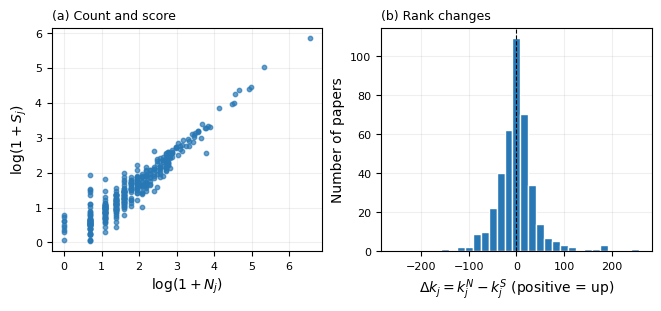

In [8]:
ASSET_DIR.mkdir(parents=True, exist_ok=True)
full_summary_figure = plot_full_paper_summary(
    papers, size=(6.5, 3.0), log_axes=True,
    save_path=ASSET_DIR / "paper_summary.pdf",
)
plt.show()


## 9. Output the threshold-selected comparison figure

Rerun after changing the bounds. Highlight the same three cases shown below.


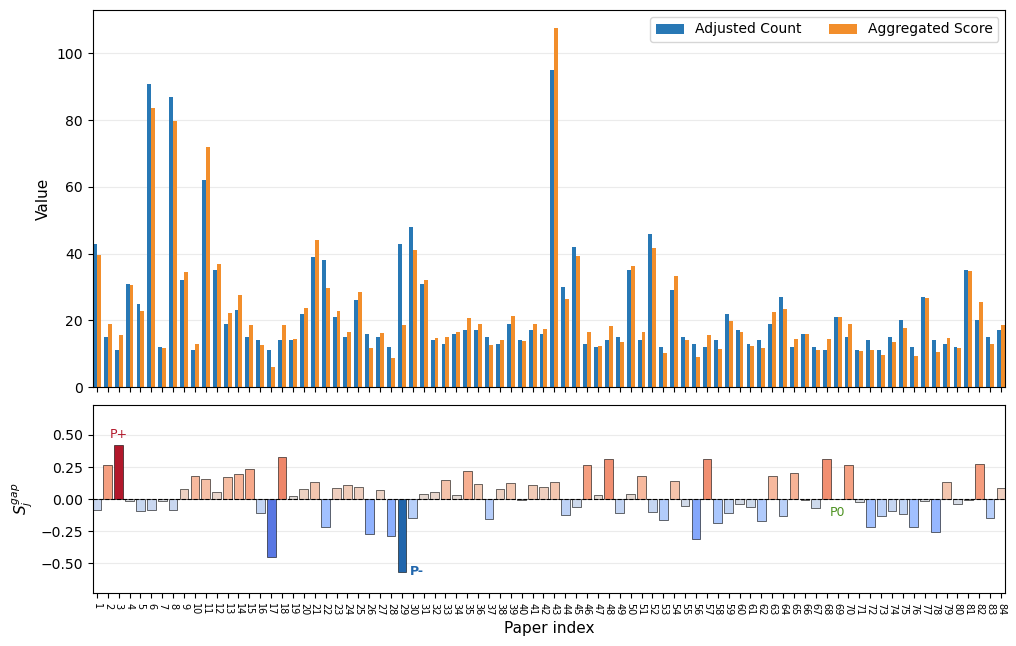

In [9]:
comparison_figure = plot_count_score_comparison(
    result["papers"], save_path=ASSET_DIR / "count_score.pdf"
)
plt.show()


## 10. Output the maximum-gap case

Select automatically from the current display subset, not a hard-coded paper ID. The final cumulative score-minus-count equals this case's paper-level gap before division by N.


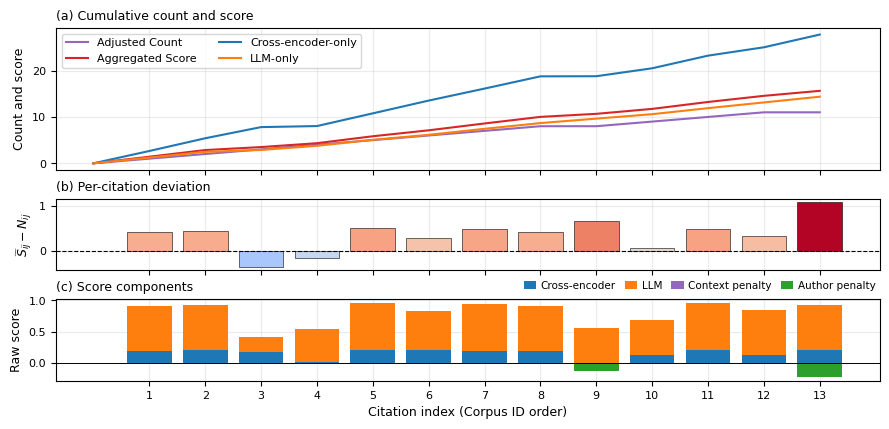

In [10]:
positive_case = result["cases"].loc[result["cases"]["case"].eq("largest_positive_gap")].iloc[0]
positive_figure, positive_details = plot_count_score_detail(
    result["citations"], positive_case["id"], "Maximum gap",
    save_path=ASSET_DIR / "detail_pos.pdf",
)
np.testing.assert_allclose(positive_details["score_mm"].sum(), positive_case["total_score"])
plt.show()


## 11. Output the minimum-gap case


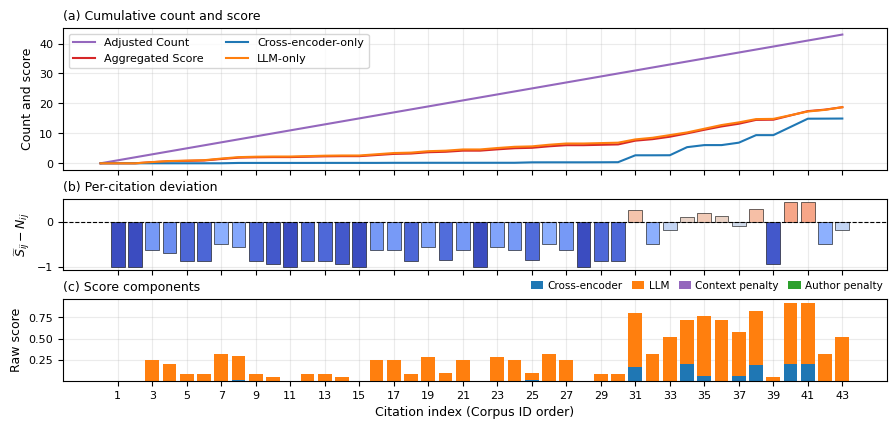

In [11]:
negative_case = result["cases"].loc[result["cases"]["case"].eq("largest_negative_gap")].iloc[0]
negative_figure, negative_details = plot_count_score_detail(
    result["citations"], negative_case["id"], "Minimum gap",
    save_path=ASSET_DIR / "detail_neg.pdf",
)
np.testing.assert_allclose(negative_details["score_mm"].sum(), negative_case["total_score"])
plt.show()


## 12. Output the case closest to equal count and score


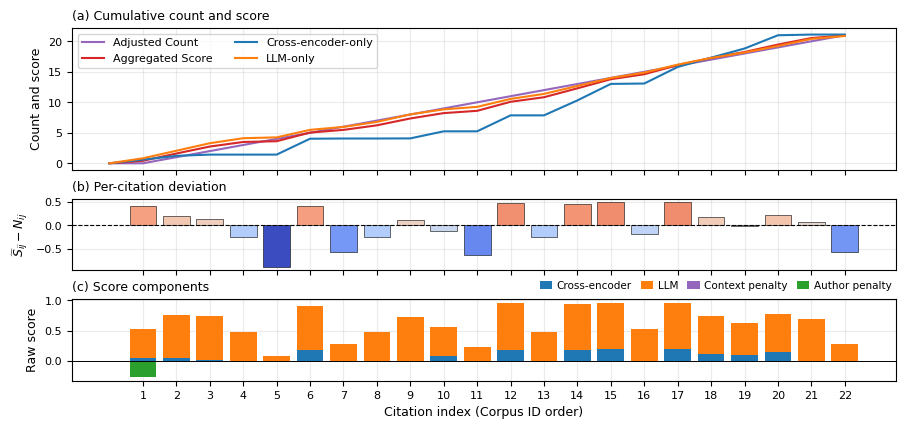

In [12]:
neutral_case = result["cases"].loc[result["cases"]["case"].eq("closest_to_equal")].iloc[0]
neutral_figure, neutral_details = plot_count_score_detail(
    result["citations"], neutral_case["id"], "Closest to zero",
    save_path=ASSET_DIR / "detail_mid.pdf",
)
np.testing.assert_allclose(neutral_details["score_mm"].sum(), neutral_case["total_score"])
plt.show()


## 13. Save case statistics and reproducibility metadata

The default case table replaces identifiers with P+, P-, and P0. Record-level exports (including IDs and scores, but no abstracts or PDF files) require `EXPORT_RECORDS=True` and remain local; assess redistribution permissions separately. Aggregate CSV/LaTeX outputs and figures use stable filenames. Rerunning the selection and output cells overwrites this experiment's derived outputs only.


In [13]:
case_statistics = result["cases"].copy()
case_statistics["Case"] = case_statistics["case"].map(lambda x: CASE_STYLE[x][0])
case_statistics = case_statistics.rename(columns={"count": "N", "score_raw": "S",
                                                  "total_score": "S_normalized", "diff": "S_gap"})
case_statistics = case_statistics[[
    "Case", "N", "S", "S_normalized", "S_gap", "retained_pairs",
    "retained_context_pairs", "retained_abstract_pairs", "self_citation_count",
]]
display(case_statistics)
if SAVE_RESULTS:
    OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
    case_statistics.to_csv(OUTPUT_DIR / "case_statistics.csv", index=False)
    # Hash numeric/branch inputs without exporting article text or author identities.
    input_columns = ["citing_id", "cited_id", "branch", "cross", "llm", "U"]
    input_hash = hashlib.sha256(pd.util.hash_pandas_object(
        scored_citations[input_columns].sort_values(["cited_id", "citing_id"]),
        index=False,
    ).values.tobytes()).hexdigest()
    notebook = json.loads((SRC_DIR / "count_score.ipynb").read_text(encoding="utf-8"))
    code_text = "\n".join("".join(c["source"]) for c in notebook["cells"] if c["cell_type"] == "code")
    manifest = {
        "database_query_utc": database_query_utc,
        "seed_input": "sample/seed_papers_final.xlsx",
        "seed_sha256": hashlib.sha256(SEED_FILE.read_bytes()).hexdigest(),
        "code_sha256": hashlib.sha256(code_text.encode("utf-8")).hexdigest(),
        "cohort_values_sha256": input_hash,
        "alpha": ALPHA, "beta": BETA, "lambda_final": CONTEXT_DISCOUNT,
        "expected_pairs": EXPECTED_PAIRS, "eligible_pairs": len(scored_citations),
        "context_pairs": int(scored_citations["branch"].eq("context").sum()),
        "abstract_only_pairs": int(scored_citations["branch"].eq("abstract").sum()),
        "self_citation_pairs": int(scored_citations["U"].le(0.5).sum()),
        "lower_count_exclusive": result["lower_count"],
        "upper_count_exclusive": result["upper_count"],
        "display_papers": len(result["papers"]),
        "normalization_factors": result["factors"],
        "base_random_seed_from_environment": RANDOM_STATE,
        "randomization": "none; deterministic Corpus ID tie-breaking",
        "eligibility": "Same author-valid text-ready cohort as author_independence.ipynb; "
                       "valid active semantic scores and recorded U; no U imputation",
        "count_rule": "U > 0.5 on eligible pairs",
        "score_formula": "(alpha*cross+(1-alpha)*LLM)*context_weight*(1-beta+beta*U)",
        "case_selection": "Maximum, minimum and closest-to-zero S_gap among distinct papers",
        "gap": "(subset-mean-matched S - N) / N",
        "normalization_scope": "Threshold-selected paper subset, never individual cases",
        "single_model_comparators": "Context-discounted; no author correction; own mean-matching factors",
        "detail_order": "Ascending citing Corpus ID; not chronological",
        "rank_reference": "All papers with eligible pairs; descending average-tie ranks",
        "quartiles": "Linear interpolation; not confidence intervals",
        "record_exports_enabled": EXPORT_RECORDS,
        "figure_canvases_inches": {"summary": [6.5, 3.0], "comparison": [10, 6.3], "detail": [9, 4.3]},
        "comparison_layout": "Landscape canvas for rotated full-page placement",
        "detail_panel_hspace": 0.30,
        "figure_outputs": ["paper_summary.pdf", "count_score.pdf", "detail_pos.pdf", "detail_neg.pdf", "detail_mid.pdf"],
        "database_access": "READ ONLY REPEATABLE READ; no model calls",
        "versions": {"numpy": np.__version__, "pandas": pd.__version__},
    }
    (OUTPUT_DIR / "manifest.json").write_text(
        json.dumps(manifest, indent=2, allow_nan=False), encoding="utf-8"
    )
    if EXPORT_RECORDS:
        result["papers"].to_csv(OUTPUT_DIR / "display_papers_local.csv", index=False)
        result["cases"].to_csv(OUTPUT_DIR / "selected_cases_local.csv", index=False)
        scored_citations.drop(columns=["cited_title", "cited_doi"]).to_csv(
            OUTPUT_DIR / "citation_scores_local.csv", index=False
        )
    print("Saved aggregate tables, parameters, and metadata. No database writes.")


,Case,N,S,S_normalized,S_gap,retained_pairs,retained_context_pairs,retained_abstract_pairs,self_citation_count
2,P+,11.0,10.025933,15.632391,0.421126,13,13,0,2.0
28,P-,43.0,12.018672,18.739461,-0.564199,43,43,0,0.0
68,P0,21.0,13.451238,20.973112,-0.001280,22,22,0,1.0


Saved aggregate tables, parameters, and metadata. No database writes.
